# IEEE-CIS Fraud Detection — Exploratory Data Analysis

Goal: understand the dataset's fraud signals before modeling.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys, os

In [ ]:
data_data_folder_path = '../data/'
train_identity = pd.read_csv(f'{data_folder_path}train_identity.csv')
train_transaction = pd.read_csv(f'{data_folder_path}train_transaction.csv')
test_identity = pd.read_csv(f'{data_folder_path}test_identity.csv')
test_transaction = pd.read_csv(f'{data_folder_path}test_transaction.csv')

# Merge the data
train_data = pd.merge(train_transaction, train_identity, on='TransactionID', how='left')
test_data = pd.merge(test_transaction, test_identity, on='TransactionID', how='left')

In [10]:
print(f"{len(train_transaction):,} transactions | fraud rate: {train_transaction['isFraud'].mean():.4%}")
print(f"{len(train_identity):,} rows with identity data ({len(train_identity)/len(train_transaction):.1%} of transactions)")
print(f"Merged shape: {train_data.shape}")
print(f'There are {train_data.isnull().any().sum()} columns in the data with NaN value.')



590,540 transactions | fraud rate: 3.4990%
144,233 rows with identity data (24.4% of transactions)
Merged shape: (590540, 434)
There are 414 columns in the data with NaN value.


In [37]:
train_transaction.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [38]:
train_identity.head()

,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0,70787.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0,98945.0,NaN,NaN,0.0,-5.0,NaN,NaN,NaN,...,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0,191631.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.0,221832.0,NaN,NaN,0.0,-6.0,NaN,NaN,NaN,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.0,7460.0,0.0,0.0,1.0,0.0,NaN,NaN,0.0,...,chrome 62.0,24.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS


In [42]:
train_transaction.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 590540 entries, 0 to 590539
Columns: 394 entries, TransactionID to V339
dtypes: float64(376), int64(4), object(14)
memory usage: 1.7+ GB


In [43]:
train_identity.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144233 entries, 0 to 144232
Data columns (total 41 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   TransactionID  144233 non-null  int64  
 1   id_01          144233 non-null  float64
 2   id_02          140872 non-null  float64
 3   id_03          66324 non-null   float64
 4   id_04          66324 non-null   float64
 5   id_05          136865 non-null  float64
 6   id_06          136865 non-null  float64
 7   id_07          5155 non-null    float64
 8   id_08          5155 non-null    float64
 9   id_09          74926 non-null   float64
 10  id_10          74926 non-null   float64
 11  id_11          140978 non-null  float64
 12  id_12          144233 non-null  object 
 13  id_13          127320 non-null  float64
 14  id_14          80044 non-null   float64
 15  id_15          140985 non-null  object 
 16  id_16          129340 non-null  object 
 17  id_17          139369 non-nul

In [45]:
def reduce_memory(df):
    '''
    Reduce the memory usage (size of the df) by changing the type of each column. 
    '''
    initial_mem = df.memory_usage().sum() / 1024**2
    print(f"The initial size is: {initial_mem:.2f} MB")
    
    for col in df.columns:
        col_type = df[col].dtype
        
        if col_type != object and col_type.name != 'category':
            c_min = df[col].min()
            c_max = df[col].max()
            
            if str(col_type)[:3] == 'int':
                if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                    df[col] = df[col].astype(np.int8)
                elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                    df[col] = df[col].astype(np.int16)
                elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                    df[col] = df[col].astype(np.int32)
                elif c_min > np.iinfo(np.int64).min and c_max < np.iinfo(np.int64).max:
                    df[col] = df[col].astype(np.int64)  
            
            else:
                if c_min > np.finfo(np.float16).min and c_max < np.finfo(np.float16).max:
                    df[col] = df[col].astype(np.float16)
                elif c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
                    df[col] = df[col].astype(np.float32)
                else:
                    df[col] = df[col].astype(np.float64)
                    

        elif col_type == object:
            df[col] = df[col].astype('category')

    final_mem = df.memory_usage().sum() / 1024**2
    print(f"Memory usage after optimization is: {final_mem:.2f} MB")
    print(f"Decreased by {100 * (initial_mem - final_mem) / initial_mem:.1f}%")
    
    return df


reduce_memory(train_data)

The initial size is: 1968.89 MB
Memory usage after optimization is: 528.37 MB
Decreased by 73.2%


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo,LogTransactionAmt,hour,total_nulls
0,2987000,0,86400,68.500000,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.242188,0,234
1,2987001,0,86401,29.000000,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.400391,0,230
2,2987002,0,86469,59.000000,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.093750,0,211
3,2987003,0,86499,50.000000,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.931641,0,227
4,2987004,0,86506,50.000000,H,4497,514.0,150.0,mastercard,102.0,...,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M,3.931641,0,137
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
590535,3577535,0,15811047,49.000000,W,6550,NaN,150.0,visa,226.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.912109,23,230
590536,3577536,0,15811049,39.500000,W,10444,225.0,150.0,mastercard,224.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.701172,23,212
590537,3577537,0,15811079,30.953125,W,12037,595.0,150.0,mastercard,224.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.464844,23,217
590538,3577538,0,15811088,117.000000,W,7826,481.0,150.0,mastercard,224.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.769531,23,211


Text(0, 0.5, 'Density')

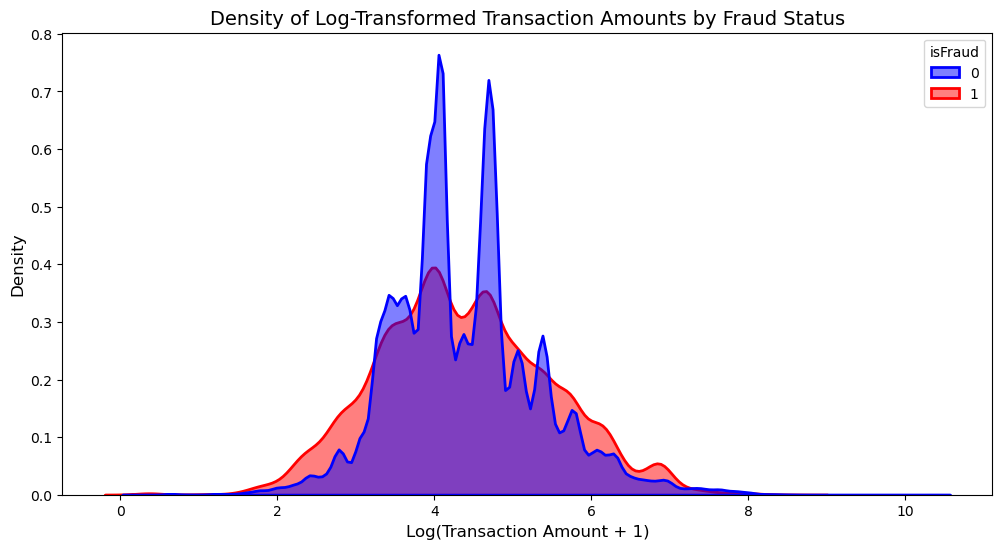

In [ ]:
# Visualize the relationship between Transaction amount and is Fraud. We took the log to handle the massive outliers
train_data['LogTransactionAmt'] = np.log1p(train_data['TransactionAmt'])

plt.figure(figsize=(12, 6))

# 3. Create the Density Plot (KDE)
sns.kdeplot(
    data=train_data, 
    x='LogTransactionAmt', 
    hue='isFraud', 
    fill=True, 
    common_norm=False, 
    palette={0: "blue", 1: "red"}, 
    alpha=0.5, 
    linewidth=2
)

plt.title('Density of Log-Transformed Transaction Amounts by Fraud Status', fontsize=14)
plt.xlabel('Log(Transaction Amount + 1)', fontsize=12)
plt.ylabel('Density', fontsize=12)

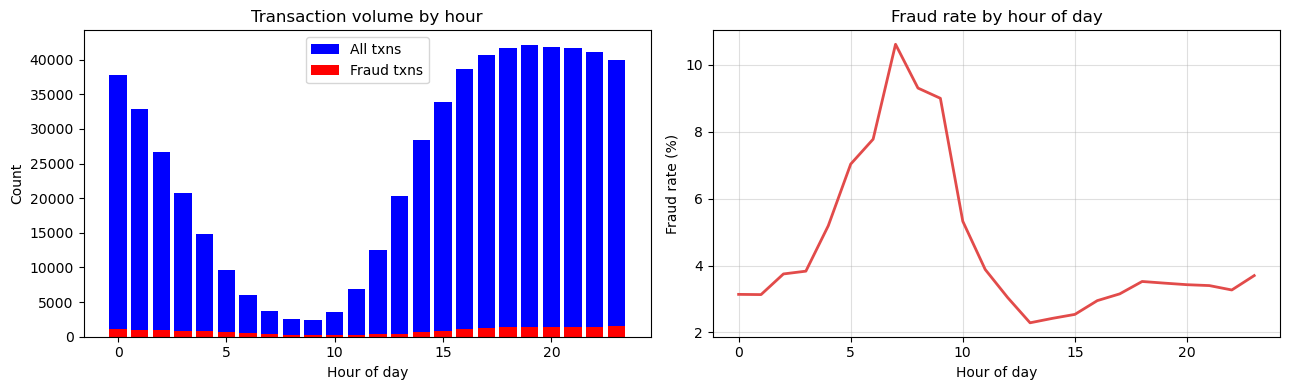

In [23]:
train_data["hour"] = (train_data["TransactionDT"] // 3600) % 24

hourly = train_data.groupby("hour")["isFraud"].agg(["sum", "count"])
hourly["rate"] = hourly["sum"] / hourly["count"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(hourly.index, hourly["count"], color="blue", label="All txns")
axes[0].bar(hourly.index, hourly["sum"],   color="red", label="Fraud txns")
axes[0].set_xlabel("Hour of day"), axes[0].set_ylabel("Count")
axes[0].set_title("Transaction volume by hour")
axes[0].legend()

axes[1].plot(hourly.index, hourly["rate"] * 100, color="#E24B4A", linewidth=2)
axes[1].set_xlabel("Hour of day"), axes[1].set_ylabel("Fraud rate (%)")
axes[1].set_title("Fraud rate by hour of day")
axes[1].grid(alpha=0.4)

plt.tight_layout()
plt.savefig("./models/eda_time_patterns.png", bbox_inches="tight")
plt.show()

Overall Pearson correlation between total nulls and fraud: -0.1317


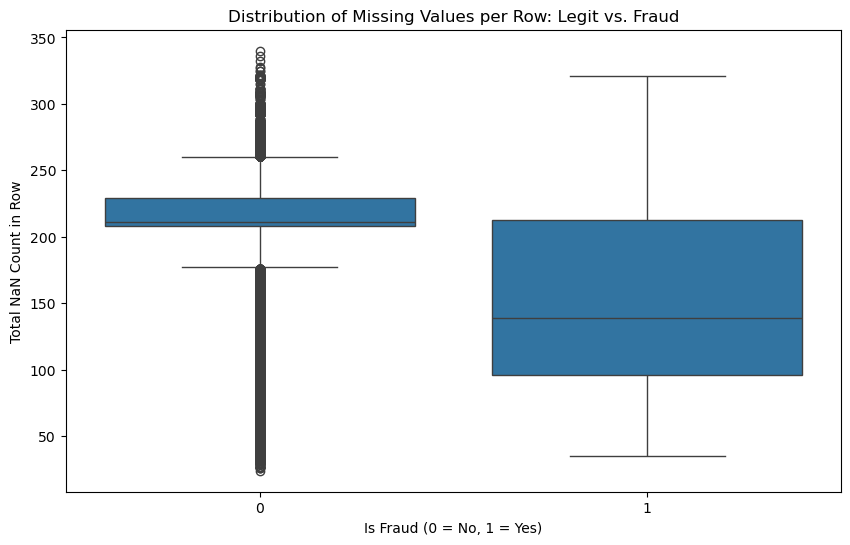

In [ ]:

train_data['total_nulls'] = train_data.isnull().sum(axis=1)

overall_corr = train_data['total_nulls'].corr(train_data['isFraud'])
print(f"Overall Pearson correlation between total nulls and fraud: {overall_corr:.4f}")

plt.figure(figsize=(10, 6))
sns.boxplot(x='isFraud', y='total_nulls', data=train_data)
plt.title('Distribution of Missing Values per Row: Legit vs. Fraud')
plt.xlabel('Is Fraud (0 = No, 1 = Yes)')
plt.ylabel('Total NaN Count in Row')
plt.show()


Fraud rate by device type:
DeviceType
mobile     0.1017
desktop    0.0652
Name: isFraud, dtype: float64

Fraud rate by card network:
card4
discover            0.0773
visa                0.0348
mastercard          0.0343
american express    0.0287
Name: isFraud, dtype: float64

Fraud rate by product code:
ProductCD
C    0.1169
S    0.0590
H    0.0477
R    0.0378
W    0.0204
Name: isFraud, dtype: float64


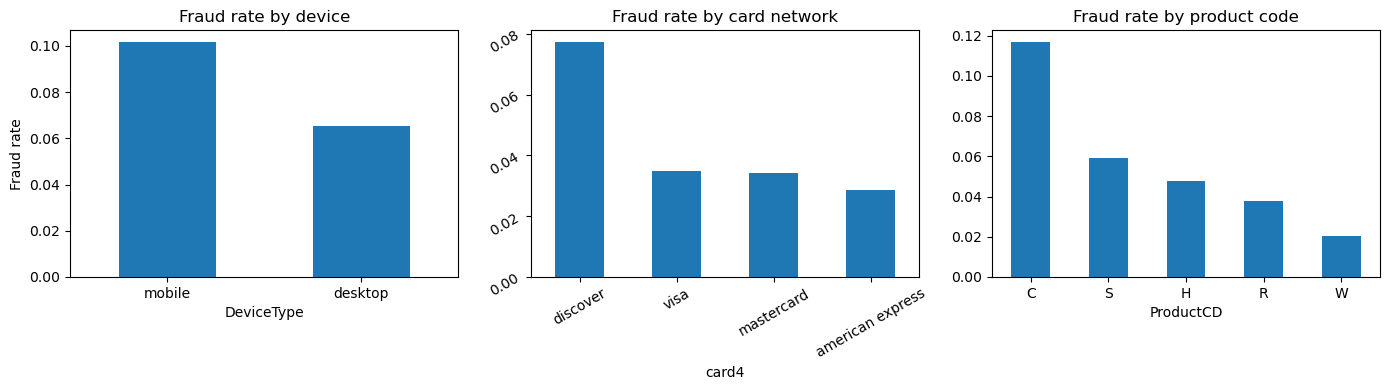

In [34]:
# Device type
device_fraud = train_data.groupby("DeviceType")["isFraud"].mean().sort_values(ascending=False)
print(f"\nFraud rate by device type:\n{device_fraud.round(4)}")

# Card network
card_fraud = train_data.groupby("card4")["isFraud"].mean().sort_values(ascending=False)
print(f"\nFraud rate by card network:\n{card_fraud.round(4)}")

# Product code
prod_fraud = train_data.groupby("ProductCD")["isFraud"].mean().sort_values(ascending=False)
print(f"\nFraud rate by product code:\n{prod_fraud.round(4)}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
device_fraud.plot(kind="bar", ax=axes[0])
axes[0].set_title("Fraud rate by device"), axes[0].set_ylabel("Fraud rate"), axes[0].tick_params(rotation=0)

card_fraud.plot(kind="bar", ax=axes[1])
axes[1].set_title("Fraud rate by card network"), axes[1].tick_params(rotation=30)

prod_fraud.plot(kind="bar", ax=axes[2])
axes[2].set_title("Fraud rate by product code"), axes[2].tick_params(rotation=0)

plt.tight_layout()
plt.show()

In [53]:
cat_col = train_data.select_dtypes(include=object).columns

for col in cat_col:
    print(col, ":")
    print(train_data[col].unique())

ProductCD :
['W' 'H' 'C' 'S' 'R']
card4 :
['discover' 'mastercard' 'visa' 'american express' nan]
card6 :
['credit' 'debit' nan 'debit or credit' 'charge card']
P_emaildomain :
[nan 'gmail.com' 'outlook.com' 'yahoo.com' 'mail.com' 'anonymous.com'
 'hotmail.com' 'verizon.net' 'aol.com' 'me.com' 'comcast.net'
 'optonline.net' 'cox.net' 'charter.net' 'rocketmail.com' 'prodigy.net.mx'
 'embarqmail.com' 'icloud.com' 'live.com.mx' 'gmail' 'live.com' 'att.net'
 'juno.com' 'ymail.com' 'sbcglobal.net' 'bellsouth.net' 'msn.com' 'q.com'
 'yahoo.com.mx' 'centurylink.net' 'servicios-ta.com' 'earthlink.net'
 'hotmail.es' 'cfl.rr.com' 'roadrunner.com' 'netzero.net' 'gmx.de'
 'suddenlink.net' 'frontiernet.net' 'windstream.net' 'frontier.com'
 'outlook.es' 'mac.com' 'netzero.com' 'aim.com' 'web.de' 'twc.com'
 'cableone.net' 'yahoo.fr' 'yahoo.de' 'yahoo.es' 'sc.rr.com' 'ptd.net'
 'live.fr' 'yahoo.co.uk' 'hotmail.fr' 'hotmail.de' 'hotmail.co.uk'
 'protonmail.com' 'yahoo.co.jp']
R_emaildomain :
[nan 'gmai

In [56]:
for i in train_data['DeviceInfo'].unique():
    print(i)

nan
SAMSUNG SM-G892A Build/NRD90M
iOS Device
Windows
MacOS
SM-G930V Build/NRD90M
BLADE A602 Build/MRA58K
XT1635-02 Build/NPN26.118-22-2
Z970
SM-N920V Build/NRD90M
Redmi Note 4 Build/MMB29M
Lenovo PB1-750M Build/S100
LT22i Build/6.2.A.1.100
rv:52.0
SM-G950U Build/NRD90M
LG-H872 Build/NRD90U
LG-K500 Build/MMB29M
SM-P550 Build/MMB29M
SM-J700M Build/MMB29K
Trident/7.0
rv:57.0
SAMSUNG SM-G930T Build/NRD90M
Blade V6 Plus Build/MRA58K
BLL-L23 Build/HUAWEIBLL-L23
KYOCERA-C6742A Build/LMY47V
F3113 Build/33.2.A.4.70
D5306 Build/19.4.A.0.182
M4 SS4457 Build/MRA58K
SM-G955U Build/NRD90M
SM-G610M Build/MMB29K
SAMSUNG SM-G935F Build/NRD90M
XT1635-01
rv:56.0
VS500
CAM-L03 Build/HUAWEICAM-L03
RCT6303W87M7 Build/MRA58K
M4 SS4451 Build/LMY47D
KFFOWI Build/LVY48F
Moto E (4) Build/NMA26.42-19
SAMSUNG
E2306 Build/26.3.A.1.33
Ilium L910 Build/MRA58K
GT-I9300
LG-H420 Build/LRX21Y
Windows NT 6.2
XT1032 Build/LPBS23.13-56-2
GT-I9060M Build/KTU84P
rv:38.0
Moto G (4) Build/NPJS25.93-14-10
SM-G530T
LGMP260 Build/